# Qwen-27B L55 Code-Subspace Mediation

The preceding experiment established that an L49 physical-side direction controls shortcut-conflict behavior in both directions and produces a prompt-specific downstream change at L55.

[实验设置与运行说明](../../../docs/experiment_notes/05_appendix_content_and_encoding/4c02decc0d3d18bb.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the L55 code-subspace mediation protocol
cell_stage('Freezing sites, supports, projection controls, cohorts, and gates')
import hashlib
import json
from datetime import datetime, timezone

MODEL_KEY = 'qwen27b'
MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_SLUG = 'Qwen__Qwen3.5-27B__373612cb'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
EXPECTED_LAYER_COUNT = 64
SEMANTIC_LAYER = 49
LABEL_LAYER = 55
CAPTURE_LAYERS = (SEMANTIC_LAYER, LABEL_LAYER)
SITE_SCOPE = 'final_prompt_token'

SEED = 20260903
DIRECTION_SEED = 20260901
LABELS = ('A', 'B', 'C')
MAPPING_VARIANTS = ('forward', 'reverse')
DONOR_TASKS = ('weight_more', 'weight_less')
CONFLICT_CELLS = ('weight_conflict', 'distance_conflict')
EXPECTED_DIRECTION_FAMILIES = 32
EXPECTED_TARGET_FAMILIES = 48
INTERVENTION_MODES = (
    'total', 'remove_code', 'remove_stale',
    'remove_random', 'code_only',
)
RECORDS_PER_VARIANT = 2 * len(INTERVENTION_MODES)
RECORDS_PER_FAMILY = len(MAPPING_VARIANTS) * RECORDS_PER_VARIANT
EXPECTED_RECORDS = EXPECTED_TARGET_FAMILIES * RECORDS_PER_FAMILY
PATCH_CONDITION_BATCH_SIZE = 1
BOOTSTRAP_REPLICATES = 10000
SIGNFLIP_REPLICATES = 100000
ALPHA = 0.05
MIN_COHORT = 8
TOTAL_SESOI_LOGODDS = 0.25
SUBSPACE_SESOI_LOGODDS = 0.05
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
NORM_RELATIVE_TOLERANCE = 0.02
IMAGE_TOKEN_ID_OVERRIDE = None

DEPTH_ROOT = PROJECT_ROOT / 'results' / 'semantic_label_depth_localization_v1'
DEPTH_SUPPORT_PATH = DEPTH_ROOT / 'depth_support.jsonl'
DEPTH_DECISION_PATH = (
    DEPTH_ROOT / 'models' / MODEL_SLUG / 'analysis' / 'depth_decision.json'
)
INVERSE_SCENE_DIR = (
    PROJECT_ROOT / 'results' / 'inverse_query_weight_route_specificity_v1'
    / 'rendered_scenes'
)
TARGET_ROOT = (
    PROJECT_ROOT / 'results' / 'targeted_shortcut_error_rescue_induction_v1'
)
TARGET_MANIFEST_PATH = TARGET_ROOT / 'shortcut_error_manifest.jsonl'
TARGET_SCENE_DIR = TARGET_ROOT / 'rendered_scenes'
TARGET_PRIOR_DECISION_PATH = (
    TARGET_ROOT / 'models' / MODEL_SLUG / 'analysis'
    / 'targeted_error_decision.json'
)
PRIOR_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_semantic_error_mediation_v1'
)
PRIOR_SHARD_DIR = PRIOR_ROOT / 'target_shards'
PRIOR_DECISION_PATH = PRIOR_ROOT / 'analysis' / 'semantic_error_decision.json'
PRIOR_CAPTURE_CONFIG_PATH = PRIOR_ROOT / 'capture_config.json'

SHARED_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_l55_code_subspace_mediation_v1'
)
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
SUPPORT_LOCK_PATH = SHARED_ROOT / 'support_lock.json'
SHARD_DIR = SHARED_ROOT / 'family_shards'
ANALYSIS_DIR = SHARED_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for path in (SHARED_ROOT, SHARD_DIR, ANALYSIS_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

protocol_identity = {
    'schema_version': 'qwen27b-l55-code-subspace-mediation-protocol-1.0',
    'analysis_status': 'frozen_mechanistic_followup',
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'semantic_site': [SEMANTIC_LAYER, SITE_SCOPE],
    'mediator_site': [LABEL_LAYER, SITE_SCOPE],
    'site_selection': 'frozen from completed depth localization',
    'direction_support': 'same locked 32-family direction support',
    'target_support': 'same locked 48-family error-control targets',
    'target_selection_uses_current_outputs': False,
    'mapping_variants': list(MAPPING_VARIANTS),
    'intervention_modes': list(INTERVENTION_MODES),
    'code_block': (
        'remove only the projection of the L49-induced L55 delta onto the '
        'current prompt-specific code-transition direction'
    ),
    'controls': (
        'remove equal-magnitude stale-mapping or deterministic random-axis '
        'vectors; transfer the isolated current-code component alone'
    ),
    'stable_rescue_cohort': (
        'both clean label mappings predict the specified shortcut semantic'
    ),
    'stable_induction_cohort': (
        'both clean label mappings predict the exact-torque semantic'
    ),
    'primary_pool': 'weight and distance conflicts pooled',
    'primary_gate': (
        'n >= 8; total lower 95% CI > 0.25; code-removal attenuation lower '
        'CI > 0.05; random/stale specificity and code-only sufficiency lower '
        'CIs > 0; '
        'both mapping-specific attenuation lower CIs > 0; sign-flip BH q < .05'
    ),
    'bootstrap_unit': 'independent physical target family',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'signflip_replicates': SIGNFLIP_REPLICATES,
    'seed': SEED,
    'interpretation_limit': (
        'A positive result localizes a response-code subspace that carries '
        'the frozen L49 steering effect. It does not establish how upstream '
        'visual evidence produced the L49 response semantic.'
    ),
}
canonical_protocol_identity = json.loads(json.dumps(
    protocol_identity, sort_keys=True
))
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == canonical_protocol_identity, (
        'Existing protocol differs. Use a new versioned output root.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': canonical_protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_ID, '@', MODEL_REVISION)
print('Frozen semantic / mediator sites:', SEMANTIC_LAYER, LABEL_LAYER)
print('Expected records:', EXPECTED_RECORDS)
print('Output:', SHARED_ROOT)


Lock the L55 code-subspace mediation protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-27B @ 373612cb4f9288fcf550b526d86d85febedd9801
Frozen semantic / mediator sites: 49 55
Expected records: 960
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_l55_code_subspace_mediation_v1


In [6]:
%%cell_progress 5/17 Verify the completed predecessor and frozen supports
cell_stage('Checking prior decision, shards, depth result, and target manifest')

for required in (
    DEPTH_SUPPORT_PATH, DEPTH_DECISION_PATH, INVERSE_SCENE_DIR,
    TARGET_MANIFEST_PATH, TARGET_SCENE_DIR, TARGET_PRIOR_DECISION_PATH,
    PRIOR_DECISION_PATH, PRIOR_CAPTURE_CONFIG_PATH, PRIOR_SHARD_DIR,
):
    assert Path(required).exists(), f'Missing prerequisite: {required}'

depth_decision = json.loads(DEPTH_DECISION_PATH.read_text(encoding='utf-8'))
assert depth_decision['model_id'] == MODEL_ID
assert depth_decision['resolved_revision'] == MODEL_REVISION
assert depth_decision['transition_decision'] == 'semantic_to_label_transition'
assert SEMANTIC_LAYER in depth_decision['semantic_layers']
assert int(depth_decision['stable_label_onset_layer']) == LABEL_LAYER

prior_decision = json.loads(PRIOR_DECISION_PATH.read_text(encoding='utf-8'))
assert prior_decision['model_id'] == MODEL_ID
assert prior_decision['resolved_revision'] == MODEL_REVISION
assert prior_decision['primary_decision'] == (
    'bidirectional_semantic_error_control_with_code_mediation'
)
assert prior_decision['rescue_passed'] and prior_decision['induction_passed']
assert prior_decision['mediation_passed'] and prior_decision['code_control_passed']

prior_shards = sorted(PRIOR_SHARD_DIR.glob('*.json'))
assert len(prior_shards) == EXPECTED_TARGET_FAMILIES
prior_capture_config = json.loads(
    PRIOR_CAPTURE_CONFIG_PATH.read_text(encoding='utf-8')
)
print('Frozen predecessor:', prior_decision['primary_decision'])
print('Prior shards:', len(prior_shards))


Verify the completed predecessor and frozen supports:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Frozen predecessor: bidirectional_semantic_error_control_with_code_mediation
Prior shards: 48


## 2. Frozen directions, targets, and prior literal flips


In [7]:
%%cell_progress 6/17 Lock disjoint direction and target supports
cell_stage('Auditing geometry disjointness and caching both image sets')
from collections import Counter, defaultdict
import shutil

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def stable_key(value, seed=SEED):
    return hashlib.sha256(f'{seed}:{value!r}'.encode('utf-8')).hexdigest()

def outcome(value):
    return 'left' if value > 0 else 'right' if value < 0 else 'balanced'

def canonical_signature(stacks):
    return tuple(sorted(
        (str(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in stacks
    ))

direction_support = read_jsonl(DEPTH_SUPPORT_PATH)
target_manifest = read_jsonl(TARGET_MANIFEST_PATH)
assert len(direction_support) == EXPECTED_DIRECTION_FAMILIES
assert len(target_manifest) == EXPECTED_TARGET_FAMILIES
assert Counter(row['diagnostic_cell'] for row in target_manifest) == {
    'weight_conflict': 24, 'distance_conflict': 24,
}

direction_signatures = {
    canonical_signature(role['stacks'])
    for row in direction_support for role in row['roles'].values()
}
target_signatures = [
    canonical_signature(row['roles']['base']['stacks'])
    for row in target_manifest
]
assert len(set(target_signatures)) == len(target_signatures)
assert not (set(target_signatures) & direction_signatures)

physics_violations = []
for row in target_manifest:
    base = row['roles']['base']['features']
    exact = str(base['outcome'])
    shortcut = str(base['strategy_predictions'][
        row['shortcut_type'] + '_only'
    ])
    if exact not in ('left', 'right') or shortcut not in ('left', 'right'):
        physics_violations.append((row['family_id'], 'nonbinary'))
    if exact == shortcut:
        physics_violations.append((row['family_id'], 'no_conflict'))
assert not physics_violations

support_identity = {
    'schema_version': 'qwen27b-semantic-error-support-1.0',
    'depth_support_sha256': sha256_file(DEPTH_SUPPORT_PATH),
    'depth_decision_identity': {
        'transition_decision': depth_decision['transition_decision'],
        'semantic_layers': depth_decision['semantic_layers'],
        'stable_label_onset_layer': depth_decision['stable_label_onset_layer'],
        'resolved_revision': depth_decision['resolved_revision'],
    },
    'target_manifest_sha256': sha256_file(TARGET_MANIFEST_PATH),
    'direction_family_ids': sorted(row['family_id'] for row in direction_support),
    'target_family_ids': sorted(row['family_id'] for row in target_manifest),
    'geometrically_disjoint': True,
}
if SUPPORT_LOCK_PATH.is_file():
    previous = json.loads(SUPPORT_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == support_identity
else:
    write_json_atomic(SUPPORT_LOCK_PATH, {
        'identity': support_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

DIRECTION_RUNTIME_DIR = Path('/content/visualtorque_semantic_direction_images_v1')
TARGET_RUNTIME_DIR = Path('/content/visualtorque_semantic_error_targets_v1')
DIRECTION_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)
TARGET_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)
direction_files = sorted({
    role['image_filename']
    for row in direction_support for role in row['roles'].values()
})
target_files = sorted({
    row['roles']['base']['image_filename'] for row in target_manifest
})
for filename in tqdm(direction_files, desc='Caching direction images', unit='image'):
    source = INVERSE_SCENE_DIR / filename
    destination = DIRECTION_RUNTIME_DIR / filename
    assert source.is_file(), source
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        shutil.copy2(source, destination)
for filename in tqdm(target_files, desc='Caching target images', unit='image'):
    source = TARGET_SCENE_DIR / filename
    destination = TARGET_RUNTIME_DIR / filename
    assert source.is_file(), source
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        shutil.copy2(source, destination)
print('Direction / target supports:', len(direction_support), len(target_manifest))
print('Geometry overlap:', len(set(target_signatures) & direction_signatures))


Lock disjoint direction and target supports:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Caching direction images:   0%|          | 0/64 [00:00<?, ?image/s]

Caching target images:   0%|          | 0/48 [00:00<?, ?image/s]

Direction / target supports: 32 48
Geometry overlap: 0


In [8]:
%%cell_progress 7/17 Load the pinned model and mapped decoder layers
cell_stage(f'Loading {MODEL_KEY} weights for L55 code-subspace mediation')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers',
        'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
print('Layer path:', LAYER_PATH)
print('Capture layers:', CAPTURE_LAYERS)


Load the pinned model and mapped decoder layers:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Capture layers: (49, 55)


## 3. Path-specific L55 code-subspace interventions


In [9]:
%%cell_progress 8/17 Define direction and counterbalanced target prompts
cell_stage('Separating physical semantics from A/B/C output codes')
import math
from visual_torque_toolkit.behavior import PromptCondition
from visual_torque_toolkit.behavior.data import BehaviorExample

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = {
    'outcome': 'Which way will the balance scale tip?',
    'weight_more': 'Which side has more total weight?',
    'weight_less': 'Which side has less total weight?',
}
SEMANTIC_TEXT = {
    'left': 'left side', 'balanced': 'equal', 'right': 'right side',
}

def task_semantic(features, task):
    if task == 'outcome':
        value = int(features['net_torque'])
    elif task == 'weight_more':
        value = int(features['weight_score'])
    elif task == 'weight_less':
        value = -int(features['weight_score'])
    else:
        raise KeyError(task)
    return outcome(value)

def mapping_by_label(semantics):
    assert set(semantics) == {'left', 'balanced', 'right'}
    return tuple({
        'position': index, 'label': LABELS[index], 'semantic': semantic,
    } for index, semantic in enumerate(semantics))

def direction_reference_mapping(row):
    semantics = ['left', 'balanced', 'right']
    offset = int(stable_key(
        f"options:{row['family_id']}", seed=DIRECTION_SEED
    )[:8], 16) % 3
    return mapping_by_label(semantics[offset:] + semantics[:offset])

def target_mappings(row):
    features = row['roles']['base']['features']
    exact = str(features['outcome'])
    shortcut = str(features['strategy_predictions'][
        row['shortcut_type'] + '_only'
    ])
    assert {exact, shortcut} == {'left', 'right'}
    balanced_label = LABELS[
        int(stable_key(f"balanced:{row['family_id']}")[:8], 16) % 3
    ]
    side_labels = [label for label in LABELS if label != balanced_label]
    mappings = {}
    for variant, exact_label, shortcut_label in (
        ('forward', side_labels[0], side_labels[1]),
        ('reverse', side_labels[1], side_labels[0]),
    ):
        semantic_by_label = {
            exact_label: exact, shortcut_label: shortcut,
            balanced_label: 'balanced',
        }
        mappings[variant] = mapping_by_label(tuple(
            semantic_by_label[label] for label in LABELS
        ))
    return mappings

def semantics_by_label(mapping):
    return tuple(
        next(item['semantic'] for item in mapping if item['label'] == label)
        for label in LABELS
    )

def label_for(mapping, semantic):
    return next(item['label'] for item in mapping if item['semantic'] == semantic)

def custom_prompt(task, mapping):
    options = '\n'.join(
        f"{item['label']}. {SEMANTIC_TEXT[item['semantic']]}"
        for item in mapping
    )
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT,
        'Question: ' + QUESTION_TEXT[task],
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_example(row, role_record, task, mapping, name, image_root, split):
    features = role_record['features']
    semantics = semantics_by_label(mapping)
    gold = task_semantic(features, task)
    return BehaviorExample(
        example_id=f"semantic_error:{row['family_id']}:{name}",
        question_id=f"semantic_error_{row['family_id']}_{name}",
        scene_id=str(role_record['scene_id']),
        condition=PromptCondition.IMAGE_RULE,
        question_kind=task,
        variant='semantic_error_mediation', split=split,
        problem_type='semantic_error_label_swap',
        outcome=gold, net_torque=int(features['net_torque']),
        prompt=custom_prompt(task, mapping),
        image_path=(image_root / role_record['image_filename']).resolve(),
        labels=LABELS,
        option_text=tuple(SEMANTIC_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=LABELS[semantics.index(gold)],
        gold_semantic=gold,
    )

def build_direction_examples(row):
    mapping = direction_reference_mapping(row)
    examples = {}
    for donor_task in DONOR_TASKS:
        for role in ('base', 'aligned_source'):
            key = f'{donor_task}__{role}'
            examples[key] = make_example(
                row, row['roles'][role], donor_task, mapping,
                key, DIRECTION_RUNTIME_DIR, 'direction_support',
            )
    return examples, mapping

def build_target_examples(row):
    mappings = target_mappings(row)
    return {
        variant: make_example(
            row, row['roles']['base'], 'outcome', mapping,
            f'target__{variant}', TARGET_RUNTIME_DIR, 'independent_target',
        )
        for variant, mapping in mappings.items()
    }, mappings

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )), fixed_prefix,
    )
    return {
        'examples': examples,
        'inputs': inputs,
        'token_by_label': token_by_label,
    }

def final_mask(prepared):
    assert len(prepared['examples']) == 1
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    mask = torch.zeros_like(attention)
    mask[int(torch.where(attention)[0][-1])] = True
    return mask

print('Direction and target prompt builders ready.')


Define direction and counterbalanced target prompts:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Direction and target prompt builders ready.


In [10]:
%%cell_progress 9/17 Define semantic steering and downstream capture scorers
cell_stage('Defining variable-layer final-token transport')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[index, prepared['token_by_label'][label]].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        probabilities = [value / sum(weights) for value in weights]
        predicted = int(np.argmax(scores))
        records.append({
            'candidate_labels': list(example.labels),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_label': example.labels[predicted],
            'predicted_semantic': example.option_semantics[predicted],
            'gold_label': example.gold_label,
            'gold_semantic': example.gold_semantic,
        })
    return records

def forward_capture(prepared, layers):
    hidden_by_layer = {}
    handles = []
    for layer in layers:
        def hook(_module, _inputs, output, layer=layer):
            hidden_by_layer[layer] = output_hidden_tensor(
                output
            ).detach().cpu().clone()
        handles.append(DECODER_LAYERS[layer].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits), hidden_by_layer

def capture_examples(examples, layers):
    scores = {}
    hidden = {name: {} for name in examples}
    masks = {}
    for name, example in examples.items():
        prepared = prepare_examples([example])
        masks[name] = final_mask(prepared)
        current_scores, current_hidden = forward_capture(prepared, layers)
        scores[name] = current_scores[0]
        for layer, tensor in current_hidden.items():
            hidden[name][layer] = tensor[0]
        del prepared, current_hidden
    return scores, hidden, masks

def selected_norm(tensor):
    return float(torch.linalg.vector_norm(tensor.float()))

def matched_random(tensor, key):
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    noise = torch.randn(tensor.shape, generator=generator, dtype=torch.float32)
    return (noise * (selected_norm(tensor) / selected_norm(noise))).to(tensor.dtype)

def forward_intervention_chunk(prepared, conditions):
    assert len(prepared['examples']) == len(conditions)
    layers = {int(row['layer_index']) for row in conditions}
    assert len(layers) == 1
    layer = next(iter(layers))
    payloads = torch.stack([row['payload_selected'] for row in conditions])
    masks = torch.stack([row['target_mask'] for row in conditions])
    modes = [row['intervention_mode'] for row in conditions]
    counts = []
    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        payload = payloads.to(device=hidden.device, dtype=hidden.dtype)
        mask = masks.to(device=hidden.device)
        modified = hidden.clone()
        counts.clear()
        for index, mode in enumerate(modes):
            current = mask[index]
            assert int(current.sum()) == int(payload[index].shape[0]) == 1
            if mode == 'add':
                modified[index, current] = hidden[index, current] + payload[index]
            elif mode == 'replace':
                modified[index, current] = payload[index]
            else:
                raise ValueError(mode)
            counts.append(int(current.sum()))
        return replace_output_hidden(output, modified)
    handle = DECODER_LAYERS[layer].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)
    for record, condition, count in zip(records, conditions, counts):
        record.update({
            key: value for key, value in condition.items()
            if key not in ('payload_selected', 'target_mask')
        })
        record['patched_tokens'] = count
    return records

def score_conditions(example, conditions):
    records = []
    grouped = defaultdict(list)
    for condition in conditions:
        grouped[int(condition['layer_index'])].append(condition)
    for layer_conditions in grouped.values():
        for start in range(0, len(layer_conditions), PATCH_CONDITION_BATCH_SIZE):
            actual = layer_conditions[start:start + PATCH_CONDITION_BATCH_SIZE]
            padded = list(actual)
            while len(padded) < PATCH_CONDITION_BATCH_SIZE:
                padded.append(padded[-1])
            prepared = prepare_examples([example] * len(padded))
            records.extend(forward_intervention_chunk(
                prepared, padded
            )[:len(actual)])
            del prepared
    return records

def centered_scores(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

def label_score(record, label):
    labels = list(record['candidate_labels'])
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    index = labels.index(label)
    other = np.delete(values, index)
    return float(values[index] - np.logaddexp.reduce(other))

def entropy(record):
    probabilities = np.asarray(record['candidate_probabilities'], dtype=float)
    return float(-np.sum(probabilities * np.log(np.clip(probabilities, 1e-12, 1))))

def cosine_similarity(left, right):
    left = left.float().reshape(-1)
    right = right.float().reshape(-1)
    denominator = torch.linalg.vector_norm(left) * torch.linalg.vector_norm(right)
    assert float(denominator) > 0
    return float(torch.dot(left, right) / denominator)

def rescale_direction(tensor, target_norm):
    norm = selected_norm(tensor)
    assert norm > 0 and target_norm > 0
    return (tensor.float() * (float(target_norm) / norm)).to(tensor.dtype)

def unit_direction(tensor):
    return rescale_direction(tensor, 1.0).float()

def score_l49_and_capture_l55(example, payload_selected, clean_l55, metadata):
    prepared = prepare_examples([example])
    mask = final_mask(prepared)
    captured = {}
    def semantic_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        payload = payload_selected.to(device=hidden.device, dtype=hidden.dtype)
        current = mask.to(hidden.device)
        modified = hidden.clone()
        modified[0, current] = hidden[0, current] + payload
        return replace_output_hidden(output, modified)
    def label_capture_hook(_module, _inputs, output):
        captured['hidden'] = output_hidden_tensor(output).detach().cpu().clone()
    semantic_handle = DECODER_LAYERS[SEMANTIC_LAYER].register_forward_hook(
        semantic_hook
    )
    label_handle = DECODER_LAYERS[LABEL_LAYER].register_forward_hook(
        label_capture_hook
    )
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        semantic_handle.remove()
        label_handle.remove()
    record = score_records(prepared, output.logits)[0]
    downstream = captured['hidden'][0][mask] - clean_l55
    record.update(metadata)
    record['patched_tokens'] = int(mask.sum())
    record['downstream_l55_norm'] = selected_norm(downstream)
    return record, downstream

print('Semantic steering and downstream capture scorers ready.')


def score_code_subspace_condition(example, condition, clean_l55):
    prepared = prepare_examples([example])
    mask = final_mask(prepared)
    measurements = {}

    def l49_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        payload = condition['l49_payload'].to(
            device=hidden.device, dtype=hidden.dtype
        )
        current = mask.to(hidden.device)
        modified = hidden.clone()
        modified[0, current] = hidden[0, current] + payload
        return replace_output_hidden(output, modified)

    def l55_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        current = mask.to(hidden.device)
        clean = clean_l55.to(device=hidden.device, dtype=hidden.dtype)
        code_unit = condition['code_unit'].to(
            device=hidden.device, dtype=torch.float32
        )
        stale_unit = condition['stale_unit'].to(
            device=hidden.device, dtype=torch.float32
        )
        random_unit = condition['random_unit'].to(
            device=hidden.device, dtype=torch.float32
        )
        delta = hidden[0, current].float() - clean.float()
        coefficient = torch.sum(delta * code_unit)
        component = coefficient * code_unit
        mode = condition['mode']
        modified = hidden.clone()
        if mode == 'total':
            selected = hidden[0, current].float()
        elif mode == 'remove_code':
            selected = hidden[0, current].float() - component
        elif mode == 'remove_stale':
            selected = hidden[0, current].float() - coefficient * stale_unit
        elif mode == 'remove_random':
            selected = hidden[0, current].float() - coefficient * random_unit
        elif mode == 'code_only':
            selected = clean.float() + component
        elif mode == 'clean_clamp':
            selected = clean.float()
        else:
            raise ValueError(mode)
        modified[0, current] = selected.to(hidden.dtype)
        measurements.update({
            'code_coefficient': float(coefficient.detach().cpu()),
            'code_component_norm': float(
                torch.linalg.vector_norm(component).detach().cpu()
            ),
            'l55_delta_norm': float(
                torch.linalg.vector_norm(delta).detach().cpu()
            ),
        })
        return replace_output_hidden(output, modified)

    handles = [
        DECODER_LAYERS[SEMANTIC_LAYER].register_forward_hook(l49_hook),
        DECODER_LAYERS[LABEL_LAYER].register_forward_hook(l55_hook),
    ]
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    record = score_records(prepared, output.logits)[0]
    record.update({
        key: value for key, value in condition.items()
        if key not in ('l49_payload', 'code_unit', 'stale_unit', 'random_unit')
    })
    record.update(measurements)
    record['patched_tokens'] = int(mask.sum())
    return record

print('L49-to-L55 code-subspace scorers ready.')


Define semantic steering and downstream capture scorers:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Semantic steering and downstream capture scorers ready.
L49-to-L55 code-subspace scorers ready.


In [11]:
%%cell_progress 10/17 Build frozen L49 semantic and L55 code libraries
cell_stage('Learning directions only from the disjoint depth support')

left_units = []
left_raw_norms = []
code_units = defaultdict(list)
code_raw_norms = []
direction_progress = tqdm(
    direction_support, desc='Building frozen direction libraries', unit='family'
)
for row in direction_progress:
    examples, mapping = build_direction_examples(row)
    scores, hidden, masks = capture_examples(examples, CAPTURE_LAYERS)
    for donor_task in DONOR_TASKS:
        base_key = f'{donor_task}__base'
        source_key = f'{donor_task}__aligned_source'
        base_semantic = task_semantic(
            row['roles']['base']['features'], donor_task
        )
        source_semantic = task_semantic(
            row['roles']['aligned_source']['features'], donor_task
        )
        assert {base_semantic, source_semantic} == {'left', 'right'}
        semantic_delta = (
            hidden[source_key][SEMANTIC_LAYER][masks[source_key]]
            - hidden[base_key][SEMANTIC_LAYER][masks[base_key]]
        )
        left_delta = semantic_delta if source_semantic == 'left' else -semantic_delta
        left_units.append(unit_direction(left_delta))
        left_raw_norms.append(selected_norm(semantic_delta))

        code_delta = (
            hidden[source_key][LABEL_LAYER][masks[source_key]]
            - hidden[base_key][LABEL_LAYER][masks[base_key]]
        )
        base_label = label_for(mapping, base_semantic)
        source_label = label_for(mapping, source_semantic)
        assert base_label != source_label
        code_units[(base_label, source_label)].append(unit_direction(code_delta))
        code_raw_norms.append(selected_norm(code_delta))
    del hidden
    torch.cuda.empty_cache()

assert len(left_units) == EXPECTED_DIRECTION_FAMILIES * len(DONOR_TASKS)
assert set(code_units) == {
    (left, right) for left in LABELS for right in LABELS if left != right
}
assert min(len(values) for values in code_units.values()) >= 4
SEMANTIC_STEERING_NORM = float(np.median(left_raw_norms))
CODE_STEERING_NORM = float(np.median(code_raw_norms))
SEMANTIC_DIRECTION = rescale_direction(
    torch.stack(left_units).mean(dim=0), SEMANTIC_STEERING_NORM
)
CODE_DIRECTIONS = {
    transition: rescale_direction(
        torch.stack(values).mean(dim=0), CODE_STEERING_NORM
    )
    for transition, values in code_units.items()
}
direction_metadata = {
    'schema_version': 'semantic-code-direction-library-1.0',
    'direction_support_sha256': sha256_file(DEPTH_SUPPORT_PATH),
    'semantic_layer': SEMANTIC_LAYER,
    'label_layer': LABEL_LAYER,
    'semantic_direction': 'left-minus-right',
    'semantic_examples': len(left_units),
    'semantic_norm': SEMANTIC_STEERING_NORM,
    'code_norm': CODE_STEERING_NORM,
    'code_transition_counts': {
        f'{left}->{right}': len(values)
        for (left, right), values in code_units.items()
    },
}
write_json_atomic(SHARED_ROOT / 'direction_library.json', direction_metadata)

# Mandatory parity check at both frozen sites.
smoke_row = target_manifest[0]
smoke_examples, smoke_mappings = build_target_examples(smoke_row)
smoke_scores, smoke_hidden, smoke_masks = capture_examples(
    smoke_examples, CAPTURE_LAYERS
)
smoke_errors = {}
for layer in CAPTURE_LAYERS:
    for variant in MAPPING_VARIANTS:
        self_record = score_conditions(smoke_examples[variant], [{
            'condition': 'self_replay', 'layer_index': layer,
            'intervention_mode': 'replace',
            'payload_selected': smoke_hidden[variant][layer][smoke_masks[variant]],
            'target_mask': smoke_masks[variant],
        }])[0]
        error = float(np.max(np.abs(
            centered_scores(self_record) - centered_scores(smoke_scores[variant])
        )))
        assert error < SMOKE_CENTERED_LOGPROB_TOLERANCE, (layer, variant, error)
        smoke_errors[f'{layer}:{variant}'] = error
print('Direction library:', direction_metadata)
print('Self replay:', smoke_errors)
del smoke_hidden
torch.cuda.empty_cache()


Build frozen L49 semantic and L55 code libraries:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Building frozen direction libraries:   0%|          | 0/32 [00:00<?, ?family/s]

Direction library: {'schema_version': 'semantic-code-direction-library-1.0', 'direction_support_sha256': 'sha256:5cfbcf507b8a5e920680bb1c53a03448487866fe1dc4fd94464df5767eb7e959', 'semantic_layer': 49, 'label_layer': 55, 'semantic_direction': 'left-minus-right', 'semantic_examples': 64, 'semantic_norm': 13.43345308303833, 'code_norm': 24.639636993408203, 'code_transition_counts': {'A->B': 16, 'B->A': 16, 'A->C': 8, 'C->A': 8, 'B->C': 8, 'C->B': 8}}
Self replay: {'49:forward': 0.0, '49:reverse': 0.0, '55:forward': 0.0, '55:reverse': 0.0}


In [12]:
%%cell_progress 11/17 Capture total, blocked, control, and code-only states
cell_stage('Running frozen current-code subspace mediation tests')

capture_identity = {
    'schema_version': 'qwen27b-l55-code-subspace-capture-1.0',
    'protocol_identity': canonical_protocol_identity,
    'support_identity': support_identity,
    'direction_metadata': direction_metadata,
    'prior_capture_sha256': sha256_file(PRIOR_CAPTURE_CONFIG_PATH),
    'model_id': MODEL_ID,
    'resolved_revision': adapter.metadata['resolved_revision'],
    'intervention_modes': list(INTERVENTION_MODES),
    'records_per_family': RECORDS_PER_FAMILY,
}
CAPTURE_SHA256 = 'sha256:' + hashlib.sha256(
    json.dumps(capture_identity, sort_keys=True).encode('utf-8')
).hexdigest()
config_path = SHARED_ROOT / 'capture_config.json'
if config_path.is_file():
    previous = json.loads(config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity
else:
    write_json_atomic(config_path, {
        'identity': capture_identity,
        'capture_identity_sha256': CAPTURE_SHA256,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })

# Mandatory dual-hook parity: a full L55 clean clamp must erase an L49 edit.
smoke_row = target_manifest[0]
smoke_examples, smoke_mappings = build_target_examples(smoke_row)
smoke_scores, smoke_hidden, smoke_masks = capture_examples(
    smoke_examples, CAPTURE_LAYERS
)
smoke_variant = 'forward'
smoke_features = smoke_row['roles']['base']['features']
smoke_exact = str(smoke_features['outcome'])
smoke_shortcut = str(smoke_features['strategy_predictions'][
    smoke_row['shortcut_type'] + '_only'
])
smoke_mapping = smoke_mappings[smoke_variant]
smoke_other_mapping = smoke_mappings['reverse']
smoke_transition = (
    label_for(smoke_mapping, smoke_shortcut),
    label_for(smoke_mapping, smoke_exact),
)
smoke_stale_transition = (
    label_for(smoke_other_mapping, smoke_shortcut),
    label_for(smoke_other_mapping, smoke_exact),
)
smoke_code_unit = unit_direction(CODE_DIRECTIONS[smoke_transition])
smoke_stale_unit = unit_direction(CODE_DIRECTIONS[smoke_stale_transition])
smoke_random_unit = unit_direction(matched_random(
    smoke_code_unit, 'mediation-smoke-random'
))
smoke_payload = (
    SEMANTIC_DIRECTION if smoke_exact == 'left' else -SEMANTIC_DIRECTION
)
smoke_condition = {
    'condition': 'clean_clamp_smoke', 'mode': 'clean_clamp',
    'l49_payload': smoke_payload,
    'code_unit': smoke_code_unit, 'stale_unit': smoke_stale_unit,
    'random_unit': smoke_random_unit,
}
smoke_record = score_code_subspace_condition(
    smoke_examples[smoke_variant], smoke_condition,
    smoke_hidden[smoke_variant][LABEL_LAYER][smoke_masks[smoke_variant]],
)
smoke_clamp_error = float(np.max(np.abs(
    centered_scores(smoke_record) - centered_scores(smoke_scores[smoke_variant])
)))
assert smoke_clamp_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, smoke_clamp_error
print('Full-clean-clamp parity:', smoke_clamp_error)
del smoke_hidden
torch.cuda.empty_cache()

completed_ids = set()
for path in sorted(SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    assert len(payload['records']) == RECORDS_PER_FAMILY
    completed_ids.add(payload['family_id'])
print('Completed / total:', len(completed_ids), len(target_manifest))

for row in tqdm(target_manifest, desc='L55 code-subspace mediation', unit='family'):
    family_id = str(row['family_id'])
    if family_id in completed_ids:
        continue
    examples, mappings = build_target_examples(row)
    baselines, clean_hidden, masks = capture_examples(examples, CAPTURE_LAYERS)
    features = row['roles']['base']['features']
    exact = str(features['outcome'])
    shortcut = str(features['strategy_predictions'][
        row['shortcut_type'] + '_only'
    ])
    assert {exact, shortcut} == {'left', 'right'}
    payload_by_direction = {
        'exact': SEMANTIC_DIRECTION if exact == 'left' else -SEMANTIC_DIRECTION,
        'shortcut': SEMANTIC_DIRECTION if shortcut == 'left' else -SEMANTIC_DIRECTION,
    }
    records = []
    for variant in MAPPING_VARIANTS:
        other_variant = 'reverse' if variant == 'forward' else 'forward'
        mapping = mappings[variant]
        other_mapping = mappings[other_variant]
        clean_l55 = clean_hidden[variant][LABEL_LAYER][masks[variant]]
        for direction, source_semantic, target_semantic in (
            ('exact', shortcut, exact),
            ('shortcut', exact, shortcut),
        ):
            transition = (
                label_for(mapping, source_semantic),
                label_for(mapping, target_semantic),
            )
            stale_transition = (
                label_for(other_mapping, source_semantic),
                label_for(other_mapping, target_semantic),
            )
            code_unit = unit_direction(CODE_DIRECTIONS[transition])
            stale_unit = unit_direction(CODE_DIRECTIONS[stale_transition])
            random_unit = unit_direction(matched_random(
                code_unit, f'mediator:{family_id}:{variant}:{direction}:random'
            ))
            for mode in INTERVENTION_MODES:
                condition = {
                    'family_id': family_id,
                    'diagnostic_cell': row['diagnostic_cell'],
                    'shortcut_type': row['shortcut_type'],
                    'mapping_variant': variant,
                    'direction': direction,
                    'mode': mode,
                    'condition': f'{direction}__{mode}',
                    'exact_semantic': exact,
                    'shortcut_semantic': shortcut,
                    'current_transition': list(transition),
                    'stale_transition': list(stale_transition),
                    'l49_payload': payload_by_direction[direction],
                    'l49_payload_norm': selected_norm(payload_by_direction[direction]),
                    'code_unit': code_unit,
                    'stale_unit': stale_unit,
                    'random_unit': random_unit,
                }
                records.append(score_code_subspace_condition(
                    examples[variant], condition, clean_l55
                ))
    assert len(records) == RECORDS_PER_FAMILY
    write_json_atomic(SHARD_DIR / f'{family_id}.json', {
        'schema_version': 'qwen27b-l55-code-subspace-family-shard-1.0',
        'capture_identity_sha256': CAPTURE_SHA256,
        'family_id': family_id,
        'family': row,
        'baselines': baselines,
        'mappings': {key: list(value) for key, value in mappings.items()},
        'records': records,
    })
    del clean_hidden
    torch.cuda.empty_cache()

shards = sorted(SHARD_DIR.glob('*.json'))
assert len(shards) == EXPECTED_TARGET_FAMILIES
assert sum(len(json.loads(path.read_text(encoding='utf-8'))['records'])
           for path in shards) == EXPECTED_RECORDS
print('Capture complete:', len(shards), 'families,', EXPECTED_RECORDS, 'records')


Capture total, blocked, control, and code-only states:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

Full-clean-clamp parity: 0.0
Completed / total: 0 48


L55 code-subspace mediation:   0%|          | 0/48 [00:00<?, ?family/s]

Capture complete: 48 families, 960 records


## 4. Necessity, specificity, sufficiency, and paper result


In [13]:
%%cell_progress 12/17 Release GPU and assemble flip and mediation estimands
cell_stage('Computing literal flips, total effects, blocking, and sufficiency')
import gc
del adapter
gc.collect()
torch.cuda.empty_cache()

def semantic_logprob(record, semantic):
    semantics = list(record['candidate_semantics'])
    return float(record['candidate_logprobs'][semantics.index(semantic)])

def baseline_group(baselines, exact, shortcut):
    predictions = [
        str(baselines[variant]['predicted_semantic'])
        for variant in MAPPING_VARIANTS
    ]
    if all(value == shortcut for value in predictions):
        return 'stable_shortcut_error'
    if all(value == exact for value in predictions):
        return 'stable_exact_correct'
    return 'mapping_sensitive_or_other'

def prior_lookup(records, variant, intervention):
    matches = [
        record for record in records
        if record['mapping_variant'] == variant
        and record['intervention'] == intervention
    ]
    assert len(matches) == 1
    return matches[0]

# Literal answer flips from the completed predecessor; no new model calls.
prior_flip_rows = []
for path in sorted(PRIOR_SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    family = payload['family']
    exact = str(family['roles']['base']['features']['outcome'])
    shortcut = str(family['roles']['base']['features']['strategy_predictions'][
        family['shortcut_type'] + '_only'
    ])
    group = baseline_group(payload['baselines'], exact, shortcut)
    rows = []
    for variant in MAPPING_VARIANTS:
        records = payload['patch_records']
        rows.append({
            'rescue_flip': float(prior_lookup(
                records, variant, 'l49_semantic_exact'
            )['predicted_semantic'] == exact),
            'rescue_random_flip': float(prior_lookup(
                records, variant, 'l49_random_exact'
            )['predicted_semantic'] == exact),
            'induction_flip': float(prior_lookup(
                records, variant, 'l49_semantic_shortcut'
            )['predicted_semantic'] == shortcut),
            'induction_random_flip': float(prior_lookup(
                records, variant, 'l49_random_shortcut'
            )['predicted_semantic'] == shortcut),
        })
    frame = pd.DataFrame(rows)
    prior_flip_rows.append({
        'family_id': family['family_id'],
        'diagnostic_cell': family['diagnostic_cell'],
        'baseline_group': group,
        **{column: float(frame[column].mean()) for column in frame},
    })
prior_flip_frame = pd.DataFrame(prior_flip_rows)
prior_flip_frame['rescue_flip_specific'] = (
    prior_flip_frame['rescue_flip'] - prior_flip_frame['rescue_random_flip']
)
prior_flip_frame['induction_flip_specific'] = (
    prior_flip_frame['induction_flip'] - prior_flip_frame['induction_random_flip']
)
prior_flip_frame.to_csv(ANALYSIS_DIR / 'prior_literal_flip_rates.csv', index=False)

def new_lookup(records, variant, direction, mode):
    matches = [
        record for record in records
        if record['mapping_variant'] == variant
        and record['direction'] == direction and record['mode'] == mode
    ]
    assert len(matches) == 1
    return matches[0]

family_rows = []
variant_rows = []
for path in tqdm(sorted(SHARD_DIR.glob('*.json')), desc='Mediation estimands', unit='family'):
    payload = json.loads(path.read_text(encoding='utf-8'))
    family = payload['family']
    exact = str(family['roles']['base']['features']['outcome'])
    shortcut = str(family['roles']['base']['features']['strategy_predictions'][
        family['shortcut_type'] + '_only'
    ])
    group = baseline_group(payload['baselines'], exact, shortcut)
    current_rows = []
    for variant in MAPPING_VARIANTS:
        clean = payload['baselines'][variant]
        clean_margin = semantic_logprob(clean, exact) - semantic_logprob(clean, shortcut)
        row = {
            'family_id': family['family_id'],
            'diagnostic_cell': family['diagnostic_cell'],
            'baseline_group': group,
            'mapping_variant': variant,
        }
        for direction, multiplier, desired in (
            ('exact', 1.0, exact), ('shortcut', -1.0, shortcut)
        ):
            effects = {}
            for mode in INTERVENTION_MODES:
                record = new_lookup(payload['records'], variant, direction, mode)
                margin = (
                    semantic_logprob(record, exact)
                    - semantic_logprob(record, shortcut)
                )
                effects[mode] = multiplier * (margin - clean_margin)
                row[f'{direction}__{mode}'] = effects[mode]
                row[f'{direction}__{mode}__flip'] = float(
                    record['predicted_semantic'] == desired
                )
                row[f'{direction}__{mode}__component_norm'] = float(
                    record['code_component_norm']
                )
            row[f'{direction}__attenuation_code'] = (
                effects['total'] - effects['remove_code']
            )
            row[f'{direction}__specificity_random'] = (
                effects['remove_random'] - effects['remove_code']
            )
            row[f'{direction}__specificity_stale'] = (
                effects['remove_stale'] - effects['remove_code']
            )
            row[f'{direction}__flip_attenuation'] = (
                row[f'{direction}__total__flip']
                - row[f'{direction}__remove_code__flip']
            )
        variant_rows.append(row)
        current_rows.append(row)
    frame = pd.DataFrame(current_rows)
    metric_columns = [
        column for column in frame.columns
        if column not in (
            'family_id', 'diagnostic_cell', 'baseline_group', 'mapping_variant'
        )
    ]
    family_rows.append({
        'family_id': family['family_id'],
        'diagnostic_cell': family['diagnostic_cell'],
        'baseline_group': group,
        **{column: float(frame[column].mean()) for column in metric_columns},
    })

variant_frame = pd.DataFrame(variant_rows)
family_frame = pd.DataFrame(family_rows)
variant_frame.to_csv(ANALYSIS_DIR / 'variant_estimands.csv', index=False)
family_frame.to_csv(ANALYSIS_DIR / 'family_estimands.csv', index=False)
cohort_counts = family_frame.groupby([
    'diagnostic_cell', 'baseline_group'
]).size().rename('n').reset_index()
display(cohort_counts)
display(prior_flip_frame.groupby('baseline_group')[[
    'rescue_flip', 'rescue_random_flip',
    'induction_flip', 'induction_random_flip',
]].mean().round(4))
print('Family / variant estimands:', len(family_frame), len(variant_frame))


Release GPU and assemble flip and mediation estimands:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Mediation estimands:   0%|          | 0/48 [00:00<?, ?family/s]

,diagnostic_cell,baseline_group,n
0,distance_conflict,mapping_sensitive_or_other,3
1,distance_conflict,stable_exact_correct,12
2,distance_conflict,stable_shortcut_error,9
3,weight_conflict,stable_exact_correct,12
4,weight_conflict,stable_shortcut_error,12


,rescue_flip,rescue_random_flip,induction_flip,induction_random_flip
baseline_group,,,,
mapping_sensitive_or_other,1.0000,0.4,1.0000,0.5
stable_exact_correct,1.0000,1.0,0.0833,0.0
stable_shortcut_error,0.2105,0.0,1.0000,1.0


Family / variant estimands: 48 96


In [14]:
%%cell_progress 13/17 Test code-subspace necessity, specificity, and sufficiency
cell_stage('Running family bootstrap and paired sign-flip tests')

def bootstrap_summary(values, key):
    array = np.asarray(values, dtype=float)
    array = array[np.isfinite(array)]
    result = {
        'n': int(len(array)),
        'mean': float(array.mean()) if len(array) else np.nan,
        'ci_low': np.nan, 'ci_high': np.nan,
    }
    if len(array) < 2:
        return result
    generator = np.random.default_rng(
        int(stable_key(f'bootstrap:{key}')[:16], 16) % (2**63 - 1)
    )
    draws = generator.choice(
        array, size=(BOOTSTRAP_REPLICATES, len(array)), replace=True
    ).mean(axis=1)
    result.update({
        'ci_low': float(np.quantile(draws, ALPHA / 2)),
        'ci_high': float(np.quantile(draws, 1 - ALPHA / 2)),
    })
    return result

def signflip_p(values, key):
    array = np.asarray(values, dtype=float)
    array = array[np.isfinite(array)]
    if not len(array):
        return np.nan
    observed = float(array.mean())
    generator = np.random.default_rng(
        int(stable_key(f'signflip:{key}')[:16], 16) % (2**63 - 1)
    )
    exceed = 0
    remaining = SIGNFLIP_REPLICATES
    while remaining:
        count = min(10000, remaining)
        signs = generator.choice((-1.0, 1.0), size=(count, len(array)))
        draws = (signs * array).mean(axis=1)
        exceed += int(np.count_nonzero(draws >= observed))
        remaining -= count
    return float((1 + exceed) / (SIGNFLIP_REPLICATES + 1))

def bh_adjust(values):
    values = np.asarray(values, dtype=float)
    adjusted = np.full_like(values, np.nan)
    finite = np.flatnonzero(np.isfinite(values))
    if not len(finite):
        return adjusted
    local = values[finite]
    order = np.argsort(local)
    running = 1.0
    for reverse_rank in range(len(local) - 1, -1, -1):
        local_index = order[reverse_rank]
        index = finite[local_index]
        rank = reverse_rank + 1
        running = min(running, local[local_index] * len(local) / rank)
        adjusted[index] = running
    return adjusted

rescue = family_frame[
    family_frame['baseline_group'] == 'stable_shortcut_error'
]
induction = family_frame[
    family_frame['baseline_group'] == 'stable_exact_correct'
]
primary_vectors = {}
for prefix, frame, direction in (
    ('rescue', rescue, 'exact'), ('induction', induction, 'shortcut')
):
    primary_vectors.update({
        f'{prefix}_total': frame[f'{direction}__total'],
        f'{prefix}_attenuation': frame[f'{direction}__attenuation_code'],
        f'{prefix}_random_specificity': frame[f'{direction}__specificity_random'],
        f'{prefix}_stale_specificity': frame[f'{direction}__specificity_stale'],
        f'{prefix}_code_only': frame[f'{direction}__code_only'],
    })

test_rows = []
for metric, values in primary_vectors.items():
    test_rows.append({
        'test_family': 'primary', 'mapping_variant': 'averaged',
        'metric': metric, 'primary_test': True,
        **bootstrap_summary(values, f'primary:{metric}'),
        'p_signflip': signflip_p(values, f'primary:{metric}'),
    })

for variant in MAPPING_VARIANTS:
    current = variant_frame[variant_frame['mapping_variant'] == variant]
    for prefix, group, direction in (
        ('rescue', 'stable_shortcut_error', 'exact'),
        ('induction', 'stable_exact_correct', 'shortcut'),
    ):
        values = current[
            current['baseline_group'] == group
        ][f'{direction}__attenuation_code']
        test_rows.append({
            'test_family': 'mapping_invariance',
            'mapping_variant': variant, 'metric': prefix,
            'primary_test': False,
            **bootstrap_summary(values, f'mapping:{variant}:{prefix}'),
            'p_signflip': signflip_p(values, f'mapping:{variant}:{prefix}'),
        })

# Literal flip outcomes are paper-facing secondary estimands.
for prefix, group, metric in (
    ('rescue', 'stable_shortcut_error', 'rescue_flip_specific'),
    ('induction', 'stable_exact_correct', 'induction_flip_specific'),
):
    values = prior_flip_frame[
        prior_flip_frame['baseline_group'] == group
    ][metric]
    test_rows.append({
        'test_family': 'literal_flip', 'mapping_variant': 'averaged',
        'metric': prefix, 'primary_test': False,
        **bootstrap_summary(values, f'flip:{prefix}'),
        'p_signflip': signflip_p(values, f'flip:{prefix}'),
    })

tests_frame = pd.DataFrame(test_rows)
tests_frame['q_value'] = np.nan
primary_index = tests_frame.index[tests_frame['primary_test']]
tests_frame.loc[primary_index, 'q_value'] = bh_adjust(
    tests_frame.loc[primary_index, 'p_signflip'].to_numpy(float)
)

def primary_test(metric):
    rows = tests_frame[
        (tests_frame['test_family'] == 'primary')
        & (tests_frame['metric'] == metric)
    ]
    assert len(rows) == 1
    return rows.iloc[0]

def mapping_test(variant, metric):
    rows = tests_frame[
        (tests_frame['test_family'] == 'mapping_invariance')
        & (tests_frame['mapping_variant'] == variant)
        & (tests_frame['metric'] == metric)
    ]
    assert len(rows) == 1
    return rows.iloc[0]

def direction_passed(prefix):
    total = primary_test(f'{prefix}_total')
    attenuation = primary_test(f'{prefix}_attenuation')
    required = [
        primary_test(f'{prefix}_random_specificity'),
        primary_test(f'{prefix}_stale_specificity'),
        primary_test(f'{prefix}_code_only'),
    ]
    return bool(
        total['n'] >= MIN_COHORT
        and total['ci_low'] > TOTAL_SESOI_LOGODDS
        and total['q_value'] < ALPHA
        and attenuation['ci_low'] > SUBSPACE_SESOI_LOGODDS
        and attenuation['q_value'] < ALPHA
        and all(row['ci_low'] > 0 and row['q_value'] < ALPHA for row in required)
        and all(mapping_test(variant, prefix)['ci_low'] > 0
                for variant in MAPPING_VARIANTS)
    )

rescue_passed = direction_passed('rescue')
induction_passed = direction_passed('induction')
if rescue_passed and induction_passed:
    primary_decision = 'bidirectional_l55_code_subspace_mediation'
elif rescue_passed or induction_passed:
    primary_decision = 'directional_l55_code_subspace_mediation_only'
elif len(rescue) < MIN_COHORT or len(induction) < MIN_COHORT:
    primary_decision = 'stable_mapping_cohorts_underpowered'
else:
    primary_decision = 'no_specific_l55_code_subspace_mediation'

decision_payload = {
    'schema_version': 'qwen27b-l55-code-subspace-decision-1.0',
    'model_id': MODEL_ID, 'resolved_revision': MODEL_REVISION,
    'semantic_layer': SEMANTIC_LAYER, 'mediator_layer': LABEL_LAYER,
    'primary_decision': primary_decision,
    'rescue_passed': rescue_passed, 'induction_passed': induction_passed,
    'rescue_n': int(len(rescue)), 'induction_n': int(len(induction)),
    'primary_metrics': {
        metric: json.loads(primary_test(metric).to_json())
        for metric in primary_vectors
    },
}
tests_frame.to_csv(ANALYSIS_DIR / 'code_subspace_tests.csv', index=False)
write_json_atomic(ANALYSIS_DIR / 'code_subspace_decision.json', decision_payload)
display(tests_frame.round(4))
display(pd.DataFrame([decision_payload]).drop(columns=['primary_metrics']))


Test code-subspace necessity, specificity, and sufficiency:  71%|#######   | 12/17 [00:00<?, ?cell/s]

,test_family,mapping_variant,metric,primary_test,n,mean,ci_low,ci_high,p_signflip,q_value
0,primary,averaged,rescue_total,True,21,0.6845,0.6577,0.7143,0.0000,0.0
1,primary,averaged,rescue_attenuation,True,21,0.2768,0.2500,0.3036,0.0000,0.0
2,primary,averaged,rescue_random_specificity,True,21,0.2887,0.2618,0.3155,0.0000,0.0
3,primary,averaged,rescue_stale_specificity,True,21,0.5089,0.4792,0.5387,0.0000,0.0
4,primary,averaged,rescue_code_only,True,21,0.2887,0.2560,0.3214,0.0000,0.0
5,primary,averaged,induction_total,True,24,0.6927,0.6510,0.7344,0.0000,0.0
6,primary,averaged,induction_attenuation,True,24,0.2812,0.2578,0.3047,0.0000,0.0
7,primary,averaged,induction_random_specificity,True,24,0.2786,0.2578,0.2995,0.0000,0.0
8,primary,averaged,induction_stale_specificity,True,24,0.4766,0.4401,0.5104,0.0000,0.0
9,primary,averaged,induction_code_only,True,24,0.2891,0.2500,0.3255,0.0000,0.0


,schema_version,model_id,resolved_revision,semantic_layer,mediator_layer,primary_decision,rescue_passed,induction_passed,rescue_n,induction_n
0,qwen27b-l55-code-subspace-decision-1.0,Qwen/Qwen3.5-27B,373612cb4f9288fcf550b526d86d85febedd9801,49,55,no_specific_l55_code_subspace_mediation,False,False,21,24


In [15]:
%%cell_progress 14/17 Audit support identity, projections, parity, and cohorts
cell_stage('Checking frozen identities and all projection invariants')

assert prior_decision['support_identity']['depth_support_sha256'] == sha256_file(
    DEPTH_SUPPORT_PATH
)
assert prior_decision['support_identity']['target_manifest_sha256'] == sha256_file(
    TARGET_MANIFEST_PATH
)
record_count = 0
mode_counts = Counter()
l49_norm_errors = []
nonfinite_measurements = []
for path in sorted(SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    for record in payload['records']:
        record_count += 1
        mode_counts[record['mode']] += 1
        l49_norm_errors.append(abs(
            float(record['l49_payload_norm']) - SEMANTIC_STEERING_NORM
        ) / SEMANTIC_STEERING_NORM)
        if not np.isfinite([
            record['code_coefficient'], record['code_component_norm'],
            record['l55_delta_norm'],
        ]).all():
            nonfinite_measurements.append((payload['family_id'], record['condition']))
assert record_count == EXPECTED_RECORDS
assert mode_counts == Counter({
    mode: EXPECTED_TARGET_FAMILIES * len(MAPPING_VARIANTS) * 2
    for mode in INTERVENTION_MODES
})
assert not nonfinite_measurements
maximum_l49_norm_error = float(max(l49_norm_errors))
assert maximum_l49_norm_error < NORM_RELATIVE_TOLERANCE

audit_payload = {
    'schema_version': 'qwen27b-l55-code-subspace-audit-1.0',
    'support_identity': support_identity,
    'prior_decision': prior_decision['primary_decision'],
    'direction_target_geometry_overlap': 0,
    'target_families': len(target_manifest),
    'records': record_count,
    'mode_counts': dict(mode_counts),
    'cohort_counts': {
        str(row['diagnostic_cell']) + ':' + str(row['baseline_group']): int(row['n'])
        for _, row in cohort_counts.iterrows()
    },
    'full_clean_clamp_error': smoke_clamp_error,
    'clamp_tolerance': SMOKE_CENTERED_LOGPROB_TOLERANCE,
    'maximum_l49_norm_error': maximum_l49_norm_error,
    'norm_tolerance': NORM_RELATIVE_TOLERANCE,
    'nonfinite_measurements': len(nonfinite_measurements),
}
write_json_atomic(ANALYSIS_DIR / 'robustness_audit.json', audit_payload)
display(pd.DataFrame([audit_payload]))


Audit support identity, projections, parity, and cohorts:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

,schema_version,support_identity,prior_decision,direction_target_geometry_overlap,target_families,records,mode_counts,cohort_counts,full_clean_clamp_error,clamp_tolerance,maximum_l49_norm_error,norm_tolerance,nonfinite_measurements
0,qwen27b-l55-code-subspace-audit-1.0,{'schema_version': 'qwen27b-semantic-error-sup...,bidirectional_semantic_error_control_with_code...,0,48,960,"{'total': 192, 'remove_code': 192, 'remove_sta...",{'distance_conflict:mapping_sensitive_or_other...,0.0,0.15,1.774812e-07,0.02,0


Save the paper-facing subspace-mediation figure:  82%|########2 | 14/17 [00:00<?, ?cell/s]

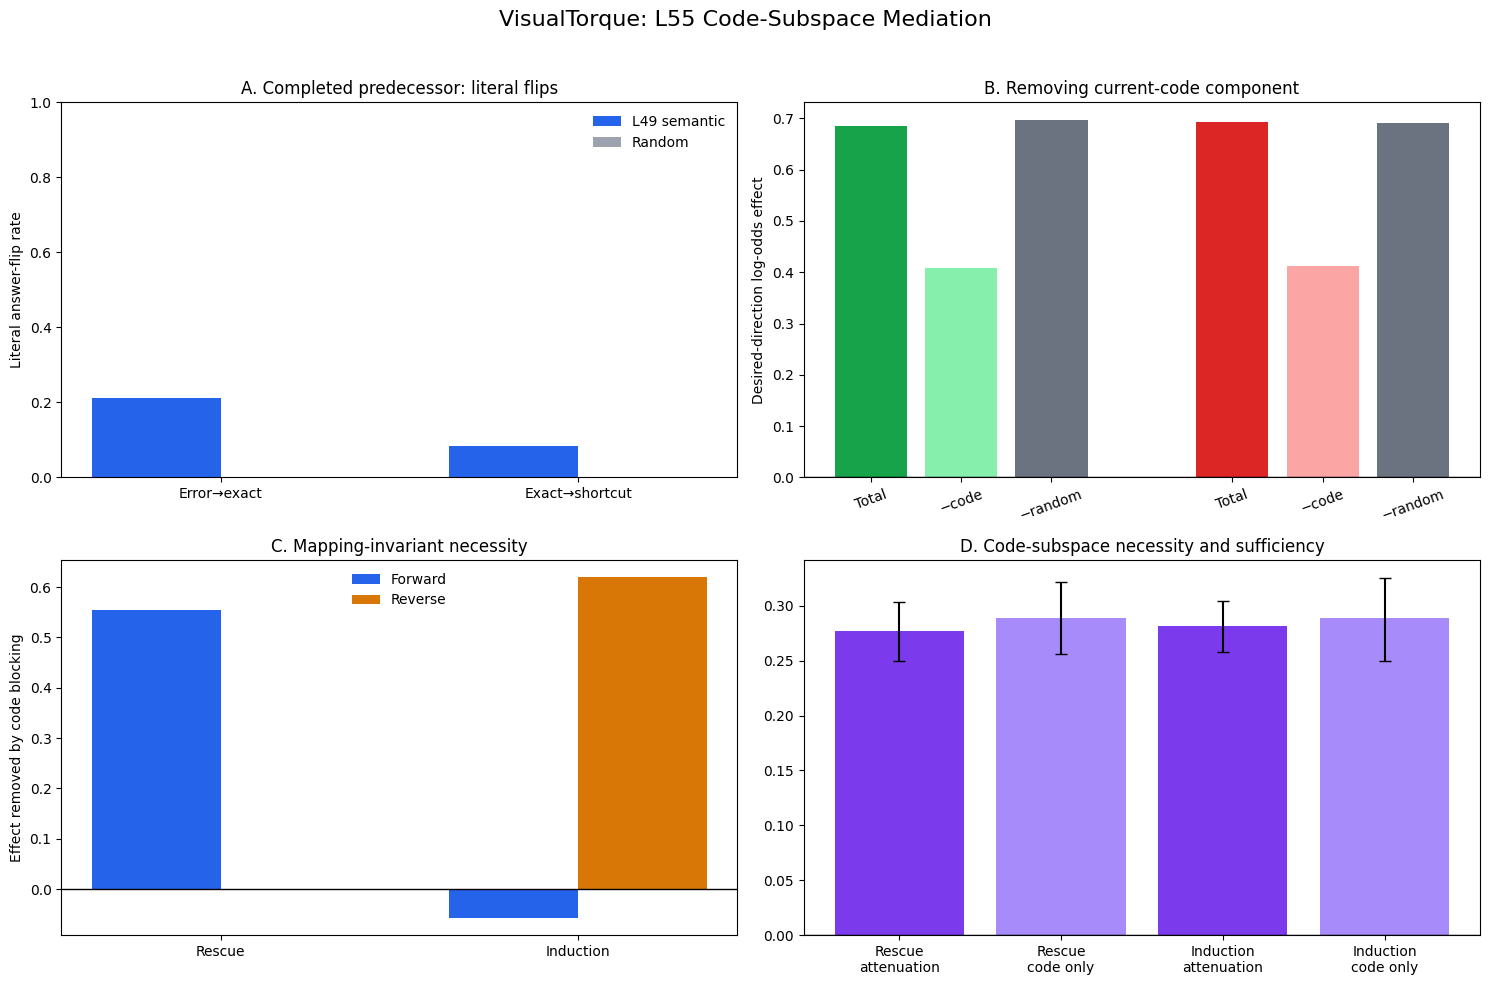

Figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_l55_code_subspace_mediation_v1/analysis/figures/l55_code_subspace_mediation.png


In [16]:
%%cell_progress 15/17 Save the paper-facing subspace-mediation figure
cell_stage('Rendering literal flips, blocking, specificity, and sufficiency')
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

flip_values = []
for group, semantic_metric, random_metric in (
    ('stable_shortcut_error', 'rescue_flip', 'rescue_random_flip'),
    ('stable_exact_correct', 'induction_flip', 'induction_random_flip'),
):
    current = prior_flip_frame[prior_flip_frame['baseline_group'] == group]
    flip_values.append((current[semantic_metric].mean(), current[random_metric].mean()))
flip_values = np.asarray(flip_values, float)
x = np.arange(2)
axes[0, 0].bar(x - .18, flip_values[:, 0], .36, label='L49 semantic', color='#2563EB')
axes[0, 0].bar(x + .18, flip_values[:, 1], .36, label='Random', color='#9CA3AF')
axes[0, 0].set_xticks(x, ['Error→exact', 'Exact→shortcut'])
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_ylabel('Literal answer-flip rate')
axes[0, 0].set_title('A. Completed predecessor: literal flips')
axes[0, 0].legend(frameon=False)

for index, (prefix, frame, direction, color) in enumerate((
    ('Rescue', rescue, 'exact', '#16A34A'),
    ('Induction', induction, 'shortcut', '#DC2626'),
)):
    values = [
        frame[f'{direction}__total'].mean(),
        frame[f'{direction}__remove_code'].mean(),
        frame[f'{direction}__remove_random'].mean(),
    ]
    positions = np.arange(3) + index * 4
    shades = (
        [color, '#86EFAC', '#6B7280'] if index == 0
        else [color, '#FCA5A5', '#6B7280']
    )
    axes[0, 1].bar(positions, values, color=shades)
axes[0, 1].set_xticks(
    [0, 1, 2, 4, 5, 6],
    ['Total', '−code', '−random', 'Total', '−code', '−random'],
    rotation=20,
)
axes[0, 1].axhline(0, color='black', linewidth=1)
axes[0, 1].set_ylabel('Desired-direction log-odds effect')
axes[0, 1].set_title('B. Removing current-code component')

mapping_values = np.asarray([
    [mapping_test(variant, prefix)['mean'] for prefix in ('rescue', 'induction')]
    for variant in MAPPING_VARIANTS
], float)
axes[1, 0].bar(x - .18, mapping_values[0], .36, label='Forward', color='#2563EB')
axes[1, 0].bar(x + .18, mapping_values[1], .36, label='Reverse', color='#D97706')
axes[1, 0].axhline(0, color='black', linewidth=1)
axes[1, 0].set_xticks(x, ['Rescue', 'Induction'])
axes[1, 0].set_ylabel('Effect removed by code blocking')
axes[1, 0].set_title('C. Mapping-invariant necessity')
axes[1, 0].legend(frameon=False)

labels = [
    'Rescue\nattenuation', 'Rescue\ncode only',
    'Induction\nattenuation', 'Induction\ncode only',
]
rows = [
    primary_test('rescue_attenuation'), primary_test('rescue_code_only'),
    primary_test('induction_attenuation'), primary_test('induction_code_only'),
]
means = np.asarray([row['mean'] for row in rows], float)
errors = np.vstack([
    means - np.asarray([row['ci_low'] for row in rows], float),
    np.asarray([row['ci_high'] for row in rows], float) - means,
])
axes[1, 1].bar(labels, means, color=['#7C3AED', '#A78BFA'] * 2)
axes[1, 1].errorbar(range(4), means, yerr=errors, fmt='none', color='black', capsize=4)
axes[1, 1].axhline(0, color='black', linewidth=1)
axes[1, 1].set_title('D. Code-subspace necessity and sufficiency')

fig.suptitle('VisualTorque: L55 Code-Subspace Mediation', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, .96))
figure_path = FIGURE_DIR / 'l55_code_subspace_mediation.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print('Figure:', figure_path)


In [17]:
%%cell_progress 16/17 Write the frozen mediation result card
cell_stage('Writing the strongest supported path-specific statement')

interpretations = {
    'bidirectional_l55_code_subspace_mediation': (
        'For both error rescue and error induction, the frozen L49 effect is '
        'selectively attenuated when its current-label code component is '
        'removed at L55, survives matched stale/random removal, and is '
        'partly reproduced by the isolated code component. This supports a '
        'prompt-specific L49 response-semantic to L55 output-code pathway.'
    ),
    'directional_l55_code_subspace_mediation_only': (
        'The L55 code subspace carries only one direction of the frozen L49 '
        'behavioral effect. Do not claim a bidirectional mediator.'
    ),
    'stable_mapping_cohorts_underpowered': (
        'The locked targets do not provide enough stable rescue and induction '
        'families for the predeclared bidirectional mediation claim.'
    ),
    'no_specific_l55_code_subspace_mediation': (
        'Removing the current-label code component is not more disruptive '
        'than matched stale or random removal, or code-only sufficiency fails.'
    ),
}
primary_decision = decision_payload['primary_decision']
decision_payload['interpretation'] = interpretations[primary_decision]
decision_payload['audit'] = audit_payload
decision_payload['support_identity'] = support_identity
decision_payload['limitations'] = [
    protocol_identity['interpretation_limit'],
    'This is a prospective intervention on reused locked target families, not a new target sample.',
    'Only the final prompt token and one model are tested.',
    'The frozen code direction is a low-dimensional approximation to the complete L55 state.',
    'Conflict-specific estimates remain secondary; the powered primary test pools both classes.',
]
decision_payload['completed_at_utc'] = datetime.now(timezone.utc).isoformat()
write_json_atomic(ANALYSIS_DIR / 'code_subspace_decision.json', decision_payload)

flip_summary = {
    'rescue_semantic': float(prior_flip_frame[
        prior_flip_frame['baseline_group'] == 'stable_shortcut_error'
    ]['rescue_flip'].mean()),
    'rescue_random': float(prior_flip_frame[
        prior_flip_frame['baseline_group'] == 'stable_shortcut_error'
    ]['rescue_random_flip'].mean()),
    'induction_semantic': float(prior_flip_frame[
        prior_flip_frame['baseline_group'] == 'stable_exact_correct'
    ]['induction_flip'].mean()),
    'induction_random': float(prior_flip_frame[
        prior_flip_frame['baseline_group'] == 'stable_exact_correct'
    ]['induction_random_flip'].mean()),
}
decision_payload['prior_literal_flip_rates'] = flip_summary
write_json_atomic(ANALYSIS_DIR / 'code_subspace_decision.json', decision_payload)

lines = [
    '# Qwen-27B L55 Code-Subspace Mediation', '',
    f'- Decision: **{primary_decision}**',
    f"- Rescue mediation: `{decision_payload['rescue_passed']}` (n={decision_payload['rescue_n']})",
    f"- Induction mediation: `{decision_payload['induction_passed']}` (n={decision_payload['induction_n']})",
    f'- Prior literal flips: `{flip_summary}`', '',
    '## Interpretation', '', interpretations[primary_decision], '',
    '## Limits', '',
]
lines.extend(f'- {value}' for value in decision_payload['limitations'])
(ANALYSIS_DIR / 'REPORT.md').write_text(
    '\n'.join(lines) + '\n', encoding='utf-8'
)
display(decision_payload)
print('Report:', ANALYSIS_DIR / 'REPORT.md')


Write the frozen mediation result card:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{'schema_version': 'qwen27b-l55-code-subspace-decision-1.0',
 'model_id': 'Qwen/Qwen3.5-27B',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'semantic_layer': 49,
 'mediator_layer': 55,
 'primary_decision': 'no_specific_l55_code_subspace_mediation',
 'rescue_passed': False,
 'induction_passed': False,
 'rescue_n': 21,
 'induction_n': 24,
 'primary_metrics': {'rescue_total': {'test_family': 'primary',
   'mapping_variant': 'averaged',
   'metric': 'rescue_total',
   'primary_test': True,
   'n': 21,
   'mean': 0.6845238079,
   'ci_low': 0.6577380858,
   'ci_high': 0.7142857042,
   'p_signflip': 9.9999e-06,
   'q_value': 9.9999e-06},
  'rescue_attenuation': {'test_family': 'primary',
   'mapping_variant': 'averaged',
   'metric': 'rescue_attenuation',
   'primary_test': True,
   'n': 21,
   'mean': 0.2767857189,
   'ci_low': 0.2499999964,
   'ci_high': 0.3035714346,
   'p_signflip': 9.9999e-06,
   'q_value': 9.9999e-06},
  'rescue_random_specificity': {'test_family': 

Report: /content/drive/MyDrive/VisualTorque/results/qwen27b_l55_code_subspace_mediation_v1/analysis/REPORT.md


In [18]:
%%cell_progress 17/17 Save paper-facing mediation tables
cell_stage('Exporting compact manuscript tables')

summary_rows = []
for metric in primary_vectors:
    row = primary_test(metric)
    summary_rows.append({
        'metric': metric, 'n': int(row['n']), 'mean': float(row['mean']),
        'ci_low': float(row['ci_low']), 'ci_high': float(row['ci_high']),
        'p_signflip': float(row['p_signflip']),
        'q_value': float(row['q_value']),
    })
summary_frame = pd.DataFrame(summary_rows)
summary_frame.to_csv(ANALYSIS_DIR / 'paper_primary_estimands.csv', index=False)

flip_paper = prior_flip_frame.groupby('baseline_group')[[
    'rescue_flip', 'rescue_random_flip',
    'induction_flip', 'induction_random_flip',
]].agg(['count', 'mean'])
flip_paper.to_csv(ANALYSIS_DIR / 'paper_literal_flip_rates.csv')

display(summary_frame.round(4))
display(flip_paper.round(4))
print('Primary decision:', primary_decision)
print('Paper outputs:', ANALYSIS_DIR)


Save paper-facing mediation tables:  94%|#########4| 16/17 [00:00<?, ?cell/s]

,metric,n,mean,ci_low,ci_high,p_signflip,q_value
0,rescue_total,21,0.6845,0.6577,0.7143,0.0,0.0
1,rescue_attenuation,21,0.2768,0.2500,0.3036,0.0,0.0
2,rescue_random_specificity,21,0.2887,0.2618,0.3155,0.0,0.0
3,rescue_stale_specificity,21,0.5089,0.4792,0.5387,0.0,0.0
4,rescue_code_only,21,0.2887,0.2560,0.3214,0.0,0.0
5,induction_total,24,0.6927,0.6510,0.7344,0.0,0.0
6,induction_attenuation,24,0.2812,0.2578,0.3047,0.0,0.0
7,induction_random_specificity,24,0.2786,0.2578,0.2995,0.0,0.0
8,induction_stale_specificity,24,0.4766,0.4401,0.5104,0.0,0.0
9,induction_code_only,24,0.2891,0.2500,0.3255,0.0,0.0


rescue_flip         rescue_random_flip       \
                                 count    mean              count mean   
baseline_group                                                           
mapping_sensitive_or_other           5  1.0000                  5  0.4   
stable_exact_correct                24  1.0000                 24  1.0   
stable_shortcut_error               19  0.2105                 19  0.0   

                           induction_flip         induction_random_flip       
                                    count    mean                 count mean  
baseline_group                                                                
mapping_sensitive_or_other              5  1.0000                     5  0.5  
stable_exact_correct                   24  0.0833                    24  0.0  
stable_shortcut_error                  19  1.0000                    19  1.0

Primary decision: no_specific_l55_code_subspace_mediation
Paper outputs: /content/drive/MyDrive/VisualTorque/results/qwen27b_l55_code_subspace_mediation_v1/analysis
